In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from datasets import load_dataset

In [8]:
emotion_data=load_dataset('dair-ai/emotion')

In [ ]:
df_train=pd.DataFrame(emotion_data['train'])
train_texts=df_train['text']
train_labels=df_train['label']

df_test=pd.DataFrame(emotion_data['test'])
test_texts=df_test['text']
test_labels=df_test['label']




In [35]:
labels=emotion_data['train'].features['label'].names
labels

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [37]:
for i in train_labels:
    print(f"Label {i}: {labels[i]}")

Label 0: sadness
Label 0: sadness
Label 3: anger
Label 2: love
Label 3: anger
Label 0: sadness
Label 5: surprise
Label 4: fear
Label 1: joy
Label 2: love
Label 0: sadness
Label 1: joy
Label 3: anger
Label 0: sadness
Label 1: joy
Label 1: joy
Label 0: sadness
Label 0: sadness
Label 0: sadness
Label 4: fear
Label 3: anger
Label 4: fear
Label 1: joy
Label 1: joy
Label 3: anger
Label 0: sadness
Label 0: sadness
Label 0: sadness
Label 3: anger
Label 1: joy
Label 1: joy
Label 4: fear
Label 5: surprise
Label 3: anger
Label 1: joy
Label 1: joy
Label 1: joy
Label 1: joy
Label 3: anger
Label 1: joy
Label 1: joy
Label 1: joy
Label 1: joy
Label 1: joy
Label 0: sadness
Label 0: sadness
Label 1: joy
Label 2: love
Label 1: joy
Label 3: anger
Label 1: joy
Label 0: sadness
Label 3: anger
Label 4: fear
Label 1: joy
Label 0: sadness
Label 0: sadness
Label 5: surprise
Label 1: joy
Label 1: joy
Label 1: joy
Label 2: love
Label 4: fear
Label 4: fear
Label 5: surprise
Label 3: anger
Label 3: anger
Label 0: s

In [ ]:
df_train_with_labels = pd.DataFrame({'text': train_texts, 'label': [labels[i] for i in train_labels]})
df_test_with_labels = pd.DataFrame({'text': test_texts, 'label': [labels[i] for i in test_labels]})

print(df_train_with_labels.head())
print(df_test_with_labels.head())


                                                text    label
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger
3  i am ever feeling nostalgic about the fireplac...     love
4                               i am feeling grouchy    anger
                                                text    label
0  im feeling rather rotten so im not very ambiti...  sadness
1          im updating my blog because i feel shitty  sadness
2  i never make her separate from me because i do...  sadness
3  i left with my bouquet of red and yellow tulip...      joy
4    i was feeling a little vain when i did this one  sadness


<Axes: xlabel='label'>

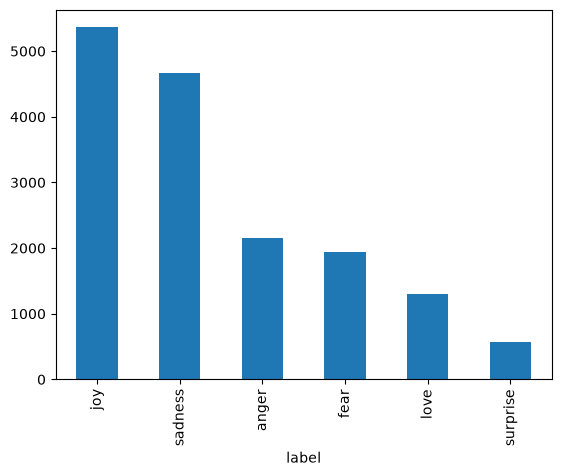

In [44]:
df_train_with_labels['label'].value_counts().plot(kind='bar')

In [46]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000

Tokenizer=Tokenizer(num_words=max_words,oov_token="<OOV>")
Tokenizer.fit_on_texts(df_train_with_labels['text'])



In [48]:
train_sequence=Tokenizer.texts_to_sequences(df_train_with_labels['text'])
test_sequence=Tokenizer.texts_to_sequences(df_test_with_labels['text'])

In [49]:
train_sequence_padded=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
test_sequence_padded=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

train_sequence_padded

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]],
      shape=(16000, 50), dtype=int32)

In [55]:
train_label_np=np.array(train_labels)
test_label_np=np.array(test_labels)

num_classes=len(labels)
num_classes

print("vocab size:", len(Tokenizer.word_index))
print("max sequence length:", train_sequence_padded.shape[1])

vocab size: 15213
max sequence length: 50


In [56]:
from sklearn.utils import class_weight


class_weight=class_weight.compute_class_weight(class_weight='balanced', classes=np.unique(train_label_np), y=train_labels)

dict(enumerate(class_weight))



{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [57]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping=EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)


In [ ]:
from pyarrow import run_end_encoded
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout,SimpleRNN,GRU

rnn_model=Sequential(
    [
        Embedding(input_dim=max_words, output_dim=128, input_length=50),
        SimpleRNN(units=128, activation='relu',return_sequences=True),
        Dropout(0.5),
        SimpleRNN(units=64, activation='relu',),
        Dropout(0.5),
        Dense(units=num_classes, activation='softmax')
    ]
)

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
rnn_model.fit(
    train_sequence_padded,
    train_label_np,
    validation_data=(test_sequence_padded, test_label_np),
    batch_size=32,
    epochs=20,
    class_weight=class_weight,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy=rnn_model.evaluate(test_sequence_padded, test_label_np)
print(f"Test Loss: {rnn_loss}, Test Accuracy: {rnn_accuracy}")

In [ ]:
lstm_model=Sequential(
    [
        Embedding(input_dim=max_words, output_dim=128, input_length=50),
        LSTM(units=128, activation='relu',return_sequences=True),
        Dropout(0.5),
        SimpleRNN(units=64, activation='relu',),
        Dropout(0.5),
        Dense(units=num_classes, activation='softmax')
    ]
)

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

lstm_model.fit(
    train_sequence_padded,
    train_label_np,
    validation_data=(test_sequence_padded, test_label_np),
    batch_size=32,
    epochs=20,
    class_weight=class_weight,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy=lstm_model.evaluate(test_sequence_padded, test_label_np)
print(f"Test Loss: {lstm_loss}, Test Accuracy: {lstm_accuracy}")

In [ ]:
gru_model=Sequential(
    [
        Embedding(input_dim=max_words, output_dim=128, input_length=50),
        GRU(units=128, activation='relu',return_sequences=True),
        Dropout(0.5),
        SimpleRNN(units=64, activation='relu',),
        Dropout(0.5),
        Dense(units=num_classes, activation='softmax')
    ]
)

gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

gru_model.fit(
    train_sequence_padded,
    train_label_np,
    validation_data=(test_sequence_padded, test_label_np),
    batch_size=32,
    epochs=20,
    class_weight=class_weight,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy=gru_model.evaluate(test_sequence_padded, test_label_np)
print(f"Test Loss: {gru_loss}, Test Accuracy: {gru_accuracy}")

In [ ]:
from tensorflow.keras.layers import Bidirectional

bigru=Sequential(
    [ Embedding(input_dim=max_words, output_dim=300, input_length=50),
      Bidirectional(GRU(units=128, activation='relu',return_sequences=True)),
      Dropout(0.5),
      Bidirectional(GRU(units=64, activation='relu',)),
      Dropout(0.5),
      Dense(num_classes, activation='softmax')
    ]
     
    )

bigru.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

bigru.summary()

In [ ]:
bigru.fit(
    train_sequence_padded,
    train_label_np,
    validation_data=(test_sequence_padded, test_label_np),
    batch_size=32,
    epochs=20,
    class_weight=class_weight,
    callbacks=[early_stopping]
)
bigru_loss, bigru_accuracy=bigru.evaluate(test_sequence_padded, test_label_np)
print(f"Test Loss: {bigru_loss}, Test Accuracy: {bigru_accuracy}")

In [ ]:
result_df=pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU','BIGRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss,bigru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy,bigru_accuracy]
}).sort_values(by='Test Accuracy',ascending=False)

result_df

In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
bigru_pred=bigru.predict(test_sequence_padded)
bigru_pred_labels=np.argmax(bigru_pred,axis=1)
sns.heatmap(confusion_matrix(test_label_np,bigru_pred_labels),annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels)

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences=Tokenizer.texts_to_sequences(sample_texts)
sample_padded=pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')
bigru_predictions=bigru.predict(sample_padded)
bigru_predictions_labels=np.argmax(bigru_predictions,axis=1)
for i,text in enumerate(sample_texts):
    print(f"Text: {text}")
    print(f"Predicted Label: {labels[bigru_predictions_labels[i]]}")
    

In [ ]:
import os
import pickle

model_dir = 'Emotion_model'
os.makedirs(model_dir, exist_ok=True)
# Save our BiGRU Model
bigru.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

# Save the tokenizer
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
    pickle.dump(Tokenizer, file)